# 06 · Sales: Feature Engineering

**Prediction moment:** the order has just been **approved** (`approved_at`). Every feature must be known at that moment.

| ✅ Known at approval | ❌ Only known later (leakage) |
|---|---|
| promised delivery date, items, price, freight, weight | carrier pickup date |
| customer & seller location, distance | delivery date |
| payment type, installments | review score |
| how this seller / route performed **on earlier, already delivered** orders | days late |

**Output:** `data/processed/sales_orders_features.parquet`, one row per delivered order, features + target `late` + train/test label.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
INTERIM, PROCESSED, REPORTS, FIG = (ROOT / "data/interim", ROOT / "data/processed",
                                     ROOT / "reports", ROOT / "reports/figures")
PROCESSED.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 12,
})

all_orders = pd.read_parquet(INTERIM / "sales_orders_clean.parquet")
df = all_orders[all_orders["is_model_row"] == 1].copy()
df["late"] = df["late"].astype(int)
df = df.sort_values("approved_at").reset_index(drop=True)
print("Delivered orders for the model:", df.shape)

feature_dictionary = []
def describe(name, how, group):
    feature_dictionary.append({"feature": name, "how_it_is_computed": how, "group": group,
                               "known_at_order_approval": "yes"})

Delivered orders for the model: (96019, 43)


## Step 1: Train/test split by time (decide first)
Oldest 80% of orders = train, newest 20% = test.

In [2]:
cutoff = df["purchased_at"].quantile(0.80)
df["split"] = np.where(df["purchased_at"] < cutoff, "train", "test")
print("Cut-off:", cutoff)
print(df.groupby("split")["late"].agg(["size", "mean"]).round(3))

Cut-off: 2018-05-26 11:53:49.600000
        size   mean
split              
test   19204  0.053
train  76815  0.089


The test period has fewer late orders. Part of this is real (deliveries improved in mid-2018), part is a data effect:
for orders bought in late August 2018, only the **fast** ones had arrived when the data was exported, so slow (late) ones are missing.
This is called **right-censoring**. It's good to mention it in your presentation; it shows you understand your data.

## Step 2: Time features

In [3]:
df["approve_hour"] = df["approved_at"].dt.hour
df["approve_weekday"] = df["approved_at"].dt.dayofweek
df["is_weekend"] = (df["approve_weekday"] >= 5).astype(int)
df["purchase_month"] = df["purchased_at"].dt.month
df["is_holiday_season"] = (((df["purchased_at"].dt.month == 11) & (df["purchased_at"].dt.day >= 15))
                           | (df["purchased_at"].dt.month == 12)).astype(int)

# durations, in days or hours
df["promised_days"] = (df["estimated_at"] - df["approved_at"]).dt.total_seconds() / 86400
df["approval_lag_hours"] = (df["approved_at"] - df["purchased_at"]).dt.total_seconds() / 3600
df["days_to_ship_limit"] = (df["shipping_limit_at"] - df["approved_at"]).dt.total_seconds() / 86400

describe("approve_hour", "hour of approval (0-23)", "time")
describe("approve_weekday", "day of week of approval (0=Mon)", "time")
describe("is_weekend", "1 if approved on Sat/Sun", "time")
describe("purchase_month", "month of purchase (1-12)", "time")
describe("is_holiday_season", "1 if purchased 15 Nov - 31 Dec (Black Friday + Christmas)", "time")
describe("promised_days", "days between approval and the promised delivery date", "time")
describe("approval_lag_hours", "hours between purchase and approval", "time")
describe("days_to_ship_limit", "days the seller has (from approval) to hand the order to the carrier", "time")
df[["promised_days", "approval_lag_hours", "days_to_ship_limit"]].describe().round(1)

,promised_days,approval_lag_hours,days_to_ship_limit
count,96019.0,96019.0,96019.0
mean,23.2,10.3,6.1
std,8.6,20.5,4.6
min,-6.7,0.0,-6.4
25%,17.9,0.2,4.0
50%,22.6,0.3,6.0
75%,28.0,14.5,6.0
max,153.6,741.4,1051.0


Quick check: are shorter promises riskier?

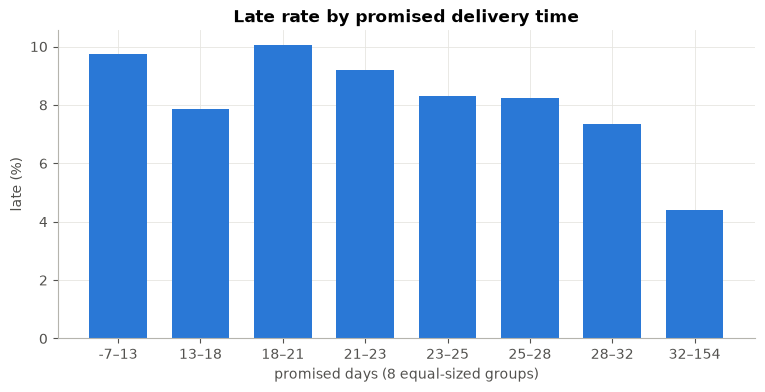

In [4]:
bucket = pd.qcut(df["promised_days"], 8)
rate = df.groupby(bucket, observed=True)["late"].mean() * 100
fig, ax = plt.subplots()
ax.bar([f"{i.left:.0f}–{i.right:.0f}" for i in rate.index], rate.values, color=BLUE, width=0.7)
ax.set_title("Late rate by promised delivery time")
ax.set_xlabel("promised days (8 equal-sized groups)")
ax.set_ylabel("late (%)")
fig.savefig(FIG / "sales_late_by_promised_days.png", dpi=120, bbox_inches="tight")
plt.show()

Yes: orders with tight promises are late far more often.

## Step 3: Geography features
**Haversine distance** = the straight-line distance between two points on the globe, from their latitude/longitude.

In [5]:
def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))     # 6371 km = Earth's radius

df["distance_km"] = haversine_km(df["customer_lat"], df["customer_lng"], df["seller_lat"], df["seller_lng"])
df["same_state"] = (df["customer_state"] == df["seller_state"]).astype(int)

# Brazil's 5 official regions
region = {
    "AC": "North", "AP": "North", "AM": "North", "PA": "North", "RO": "North", "RR": "North", "TO": "North",
    "AL": "Northeast", "BA": "Northeast", "CE": "Northeast", "MA": "Northeast", "PB": "Northeast",
    "PE": "Northeast", "PI": "Northeast", "RN": "Northeast", "SE": "Northeast",
    "DF": "Central-West", "GO": "Central-West", "MT": "Central-West", "MS": "Central-West",
    "ES": "Southeast", "MG": "Southeast", "RJ": "Southeast", "SP": "Southeast",
    "PR": "South", "RS": "South", "SC": "South",
}
df["customer_region"] = df["customer_state"].map(region).fillna("Unknown")
df["seller_region"] = df["seller_state"].map(region).fillna("Unknown")

describe("distance_km", "haversine distance between seller and customer zip (km); missing if a zip has no coordinates", "geography")
describe("same_state", "1 if seller and customer are in the same state", "geography")
print("Distance missing for", df["distance_km"].isna().sum(), "orders (LightGBM handles missing values)")
df["distance_km"].describe().round(0)

Distance missing for 477 orders (LightGBM handles missing values)


count    95542.0
mean       600.0
std        592.0
min          0.0
25%        185.0
50%        434.0
75%        798.0
max       3398.0
Name: distance_km, dtype: float64

## Step 4: Order content and payment features

In [6]:
df["freight_ratio"] = df["items_freight"] / df["items_price"].replace(0, np.nan)
df["is_multi_seller"] = (df["n_sellers"] > 1).astype(int)

content = {
    "n_items": "number of items in the order", "n_products": "distinct products", "n_sellers": "distinct sellers",
    "n_categories": "distinct product categories", "items_price": "total item price (BRL)",
    "items_freight": "total freight charged (BRL)", "freight_ratio": "freight / item price",
    "total_weight_g": "total weight of all items (g)", "total_volume_cm3": "total volume of all items (cm³)",
    "product_photos_qty": "photos of the main product", "product_description_length": "description length of the main product",
    "is_multi_seller": "1 if more than one seller",
}
for c, how in content.items():
    describe(c, how, "order content")

payment = {
    "payment_total": "total paid (BRL)", "n_payments": "number of payment parts",
    "max_installments": "max number of instalments", "used_voucher": "1 if a voucher was used",
    "approved_was_missing": "1 if approval time was missing in the raw data",
}
for c, how in payment.items():
    describe(c, how, "payment")

## Step 5: Repeat customer
Has this **person** (`customer_unique_id`) ordered before? `cumcount()` numbers each person's orders 0, 1, 2... in time order.

In [7]:
df = df.sort_values("purchased_at").reset_index(drop=True)
df["is_repeat_customer"] = (df.groupby("customer_unique_id").cumcount() > 0).astype(int)
describe("is_repeat_customer", "1 if the same customer_unique_id ordered before", "customer")
print(f"Repeat-customer orders: {df['is_repeat_customer'].mean():.1%}")

Repeat-customer orders: 3.2%


## Step 6: History features: past performance of the seller, route, category

Same idea as for incidents. For each order, we look only at **earlier orders whose outcome was already known** when this order was approved:
- an earlier order's **late/on-time** result is known once it was **delivered** (`delivered_at`)
- an earlier order's **dispatch time** is known once it was **handed to the carrier** (`carrier_at`)

And we smooth rates towards the overall average (as if adding 20 average orders), so sellers with few orders don't get extreme values.

In [8]:
PRIOR = df.loc[df["split"] == "train", "late"].mean()
M = 20

def past_mean(df, key, value_col, known_col, query_col, m=M, prior=PRIOR, window=None):
    """Smoothed mean of value_col over rows with the same key whose value was known
    (known_col) before this row's query_col. Optional window = only recent rows."""
    out_mean = np.full(len(df), np.nan)
    out_n = np.zeros(len(df), dtype=int)
    groups = df.groupby(key).groups if key else {"all": df.index}
    for k, idx in groups.items():
        sub = df.loc[idx]
        ok = sub[known_col].notna().values & sub[value_col].notna().values
        order = np.argsort(sub[known_col].values[ok])
        known_times = sub[known_col].values[ok][order]
        cum_values = np.concatenate([[0.0], np.cumsum(sub[value_col].values[ok][order])])
        q = sub[query_col].values
        hi = np.searchsorted(known_times, q, side="left")
        lo = np.zeros_like(hi) if window is None else np.searchsorted(known_times, q - window, side="left")
        n_known = hi - lo
        pos = df.index.get_indexer(idx)
        out_n[pos] = n_known
        out_mean[pos] = (cum_values[hi] - cum_values[lo] + m * prior) / (n_known + m)
    return out_mean, out_n

df = df.reset_index(drop=True)

# seller, category, route: all-time past late rate
df["route"] = df["seller_state"].fillna("?") + "→" + df["customer_state"].fillna("?")
for key, label in [("main_seller_id", "seller"), ("main_category", "category"), ("route", "route"),
                   ("customer_state", "customer_state")]:
    df[f"{label}_past_late_rate"], _ = past_mean(df, key, "late", "delivered_at", "approved_at")
    describe(f"{label}_past_late_rate", f"smoothed late rate of earlier orders with the same {key}, delivered before this approval (m=20)", "history")

# seller's usual dispatch time (days from approval to carrier pickup; negative clipped to 0)
df["_dispatch_days"] = ((df["carrier_at"] - df["approved_at"]).dt.total_seconds() / 86400).clip(lower=0)
prior_dispatch = df.loc[df["split"] == "train", "_dispatch_days"].mean()
df["seller_past_dispatch_days"], _ = past_mean(df, "main_seller_id", "_dispatch_days", "carrier_at", "approved_at",
                                               prior=prior_dispatch)
describe("seller_past_dispatch_days", "smoothed average days the seller took to hand earlier orders to the carrier", "history")

df[["main_seller_id", "approved_at", "seller_past_late_rate", "seller_past_dispatch_days", "route_past_late_rate"]].tail()

,main_seller_id,approved_at,seller_past_late_rate,seller_past_dispatch_days,route_past_late_rate
96014,5f2684dab12e59f83bef73ae57724e45,2018-08-29 12:35:17,0.067102,2.124781,0.061291
96015,67bf6941ba2f1fa1d02c375766bc3e53,2018-08-29 14:31:07,0.110904,2.476902,0.045515
96016,2a84855fd20af891be03bc5924d2b453,2018-08-29 14:30:23,0.034146,1.726514,0.032722
96017,7d7866a99a8656a42c7ff6352a433410,2018-08-29 15:05:22,0.073781,2.567515,0.061325
96018,9f505651f4a6abe901a56cdc21508025,2018-08-29 15:10:26,0.051927,1.049734,0.061325


**Recent history: an experiment that did NOT work.** Because late rates drift (Black Friday, Feb–Mar 2018), we also tried "recent" features:
- late rate of **all** orders delivered in the previous 7 days
- late rate of orders to the **same customer state** delivered in the previous 14 days

They worked for incidents, but here they made the test AUC **worse** (about 0.67 with them vs 0.71 without).
The late-delivery spikes were caused by sudden outside events (Black Friday, carrier problems). By the time the "recent late rate" rises, the spike is nearly over,
so the model mainly learned to recognise *which weeks* were bad in the training period, and that doesn't carry over to new weeks.

So we compute them (useful for a dashboard chart) but mark them with `_` as **helper columns, not features**.
**Lesson:** a feature idea is a guess. Keep it only if it improves the score on the *test* period.

In [9]:
df["_recent_late_rate_7d"], _ = past_mean(df, None, "late", "delivered_at", "approved_at", window=np.timedelta64(7, "D"))
df["_state_recent_late_rate_14d"], _ = past_mean(df, "customer_state", "late", "delivered_at", "approved_at",
                                                 window=np.timedelta64(14, "D"))

**Seller workload:** how many orders did this seller receive in the last 7 and 30 days? (A fixed window, so no "hidden clock".)

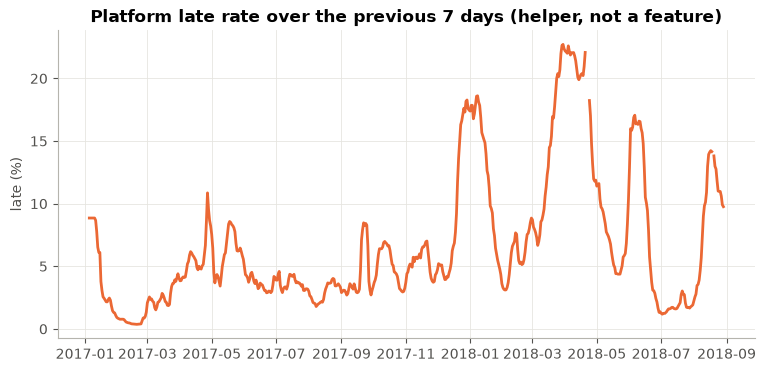

In [10]:
def count_in_window(times_sorted, query_times, window):
    return np.searchsorted(times_sorted, query_times, side="left") - np.searchsorted(times_sorted, query_times - window, side="left")

df["seller_orders_last_7d"] = 0
df["seller_orders_last_30d"] = 0
for s, idx in df.groupby("main_seller_id").groups.items():
    times = np.sort(df.loc[idx, "purchased_at"].values)
    q = df.loc[idx, "approved_at"].values
    df.loc[idx, "seller_orders_last_7d"] = count_in_window(times, q, np.timedelta64(7, "D"))
    df.loc[idx, "seller_orders_last_30d"] = count_in_window(times, q, np.timedelta64(30, "D"))
describe("seller_orders_last_7d", "orders the main seller received in the 7 days before approval", "workload")
describe("seller_orders_last_30d", "orders the main seller received in the 30 days before approval", "workload")

daily = df.set_index("approved_at")["_recent_late_rate_7d"].resample("D").mean() * 100
fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, color=ORANGE, linewidth=2)
ax.set_title("Platform late rate over the previous 7 days (helper, not a feature)")
ax.set_ylabel("late (%)")
plt.show()

## Step 7: Text categories → model categories
Top values chosen from the **training period only**; the rest become `"Other"`.

In [11]:
def top_n_or_other(df, col, n):
    top = df.loc[df["split"] == "train", col].value_counts().head(n).index
    return df[col].where(df[col].isin(top), "Other")

cat_plan = {"customer_state": 27, "seller_state": 27, "customer_region": 6, "seller_region": 6,
            "main_category": 40, "main_payment_type": 5}
for col, n in cat_plan.items():
    df[f"{col}_cat"] = top_n_or_other(df, col, n).astype("category")
    describe(f"{col}_cat", f"{col}, top {n} values from training period, rest = 'Other'", "category")
    print(f"{col:18s} distinct before: {df[col].nunique():>3}   after: {df[f'{col}_cat'].nunique():>3}")

customer_state     distinct before:  27   after:  27
seller_state       distinct before:  22   after:  22
customer_region    distinct before:   5   after:   5
seller_region      distinct before:   5   after:   5
main_category      distinct before:  74   after:  41
main_payment_type  distinct before:   4   after:   4


## Step 8: Build, check and save the feature table

In [12]:
feature_cols = [f["feature"] for f in feature_dictionary]
final = df[["order_id", "purchased_at", "approved_at", "split"] + feature_cols + ["late"]].copy()

assert final["order_id"].is_unique
leaky = {"delivered_at", "carrier_at", "review_score", "days_late", "_dispatch_days", "order_status"} & set(final.columns)
assert not leaky, f"Leaky columns: {leaky}"
print("No leakage columns ✔")
print("Features:", len(feature_cols))
na = final[feature_cols].isna().sum()
print("Features with missing values:", na[na > 0].to_dict())

final.to_parquet(PROCESSED / "sales_orders_features.parquet", index=False)
fd = pd.DataFrame(feature_dictionary)
fd.to_csv(REPORTS / "sales_feature_dictionary.csv", index=False)
print("Saved data/processed/sales_orders_features.parquet", final.shape)
fd

No leakage columns ✔
Features: 41
Features with missing values: {'distance_km': 477}
Saved data/processed/sales_orders_features.parquet (96019, 46)


,feature,how_it_is_computed,group,known_at_order_approval
0,approve_hour,hour of approval (0-23),time,yes
1,approve_weekday,day of week of approval (0=Mon),time,yes
2,is_weekend,1 if approved on Sat/Sun,time,yes
3,purchase_month,month of purchase (1-12),time,yes
4,is_holiday_season,1 if purchased 15 Nov - 31 Dec (Black Friday +...,time,yes
5,promised_days,days between approval and the promised deliver...,time,yes
6,approval_lag_hours,hours between purchase and approval,time,yes
7,days_to_ship_limit,days the seller has (from approval) to hand th...,time,yes
8,distance_km,haversine distance between seller and customer...,geography,yes
9,same_state,1 if seller and customer are in the same state,geography,yes


➡ Next: **07_baseline_check.ipynb**, a quick model on both tables to prove the features work and contain no leakage.